# Penerapan Visualisasi Data
## Dataset Kunjungan Objek Wisata Jawa Timur 2025

**Kolom yang terdapat dalam dataset ini:**
- **id_kunjungan:** nomor identifikasi unik untuk setiap catatan kunjungan.
- **tanggal:** tanggal kunjungan.
- **destinasi:** nama objek wisata.
- **kota:** kota/kabupaten lokasi objek wisata.
- **jenis_wisata:** kategori wisata (Gunung, Taman Rekreasi, Pantai, Air Terjun, Budaya & Sejarah).
- **jumlah_pengunjung:** jumlah pengunjung pada hari tersebut.
- **harga_tiket:** harga tiket masuk per orang (Rupiah).
- **lama_kunjungan_jam:** rata-rata lama kunjungan (jam).
- **rating:** penilaian pengunjung (skala 1-5).
- **cuaca:** kondisi cuaca (Cerah, Berawan, Hujan).

> Dataset ini dibuat sendiri (data simulasi) untuk latihan visualisasi.

## 1. Import Libraries

In [1]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Load Dataset

In [2]:
dataset = pd.read_excel('/content/drive/MyDrive/Colab Notebooks/data_kunjungan_wisata.xlsx')
print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)
print('Lima data teratas:')
print(dataset.head())

Ukuran dataset: 100 baris dan 10 kolom

Lima data teratas:
  id_kunjungan    tanggal           destinasi         kota      jenis_wisata  \
0        KJ001 2025-01-03        Jatim Park 2         Batu    Taman Rekreasi   
1        KJ002 2025-01-04  Pantai Balekambang       Malang            Pantai   
2        KJ003 2025-01-08    Goa Selomangleng       Kediri  Budaya & Sejarah   
3        KJ004 2025-01-15        Gunung Bromo  Probolinggo            Gunung   
4        KJ005 2025-01-17     Batu Secret Zoo         Batu    Taman Rekreasi   

   jumlah_pengunjung  harga_tiket  lama_kunjungan_jam  rating    cuaca  
0                440       150000                 1.6     4.4  Berawan  
1                350        20000                 1.6     3.4  Berawan  
2                 60        10000                 3.1     4.1    Hujan  
3                290        35000                 4.8     4.1  Berawan  
4                440       130000                 3.0     4.5    Cerah  


### 3. Menambahkan kolom bulan_kunjungan pada dataset

Kolom bulan_kunjungan dibuat dari tanggal dalam format tahun-bulan agar data bisa dikelompokkan per bulan.

In [3]:
dataset['tanggal'] = pd.to_datetime(dataset['tanggal'])
dataset['bulan_kunjungan'] = dataset['tanggal'].apply(lambda x: x.strftime('%Y-%m'))
print(dataset.head())

  id_kunjungan    tanggal           destinasi         kota      jenis_wisata  \
0        KJ001 2025-01-03        Jatim Park 2         Batu    Taman Rekreasi   
1        KJ002 2025-01-04  Pantai Balekambang       Malang            Pantai   
2        KJ003 2025-01-08    Goa Selomangleng       Kediri  Budaya & Sejarah   
3        KJ004 2025-01-15        Gunung Bromo  Probolinggo            Gunung   
4        KJ005 2025-01-17     Batu Secret Zoo         Batu    Taman Rekreasi   

   jumlah_pengunjung  harga_tiket  lama_kunjungan_jam  rating    cuaca  \
0                440       150000                 1.6     4.4  Berawan   
1                350        20000                 1.6     3.4  Berawan   
2                 60        10000                 3.1     4.1    Hujan   
3                290        35000                 4.8     4.1  Berawan   
4                440       130000                 3.0     4.5    Cerah   

  bulan_kunjungan  
0         2025-01  
1         2025-01  
2         2025

### 4. Menambahkan kolom gmv pada dataset

Kolom gmv dihitung dari jumlah_pengunjung × harga_tiket, yaitu nilai total tiket yang terjual pada setiap catatan kunjungan.

In [4]:
dataset['gmv'] = dataset['harga_tiket'] * dataset['jumlah_pengunjung']
print('Ukuran dataset: %d baris dan %d kolom\n' % dataset.shape)
print('Lima data teratas:')
print(dataset.head())

Ukuran dataset: 100 baris dan 12 kolom

Lima data teratas:
  id_kunjungan    tanggal           destinasi         kota      jenis_wisata  \
0        KJ001 2025-01-03        Jatim Park 2         Batu    Taman Rekreasi   
1        KJ002 2025-01-04  Pantai Balekambang       Malang            Pantai   
2        KJ003 2025-01-08    Goa Selomangleng       Kediri  Budaya & Sejarah   
3        KJ004 2025-01-15        Gunung Bromo  Probolinggo            Gunung   
4        KJ005 2025-01-17     Batu Secret Zoo         Batu    Taman Rekreasi   

   jumlah_pengunjung  harga_tiket  lama_kunjungan_jam  rating    cuaca  \
0                440       150000                 1.6     4.4  Berawan   
1                350        20000                 1.6     3.4  Berawan   
2                 60        10000                 3.1     4.1    Hujan   
3                290        35000                 4.8     4.1  Berawan   
4                440       130000                 3.0     4.5    Cerah   

  bulan_kunjung

### 5. Menambahkan data agregat

Data dikelompokkan per bulan dengan groupby lalu dijumlahkan dengan sum, sehingga 100 catatan menjadi 12 total bulanan.

In [5]:
gmv_bulanan = dataset.groupby('bulan_kunjungan')['gmv'].sum().reset_index()
print(gmv_bulanan)

   bulan_kunjungan        gmv
0          2025-01  172550000
1          2025-02  285600000
2          2025-03  285330000
3          2025-04  308640000
4          2025-05  304350000
5          2025-06  378800000
6          2025-07  356300000
7          2025-08  306930000
8          2025-09  162490000
9          2025-10  240000000
10         2025-11  159705000
11         2025-12  461450000


### 6. Visualisasi 1 - Membuat Line Chart Trend Pertumbuhan GMV

**Keterangan:** Line chart ini menunjukkan total GMV tiap bulan sepanjang 2025 (sumbu x: bulan, sumbu y: GMV) untuk melihat tren naik-turunnya.

**Insight:** GMV tertinggi terjadi pada Desember 2025 (Rp461 juta) dan terendah pada November 2025 (Rp160 juta), dengan Juni sebagai puncak kedua (Rp379 juta).

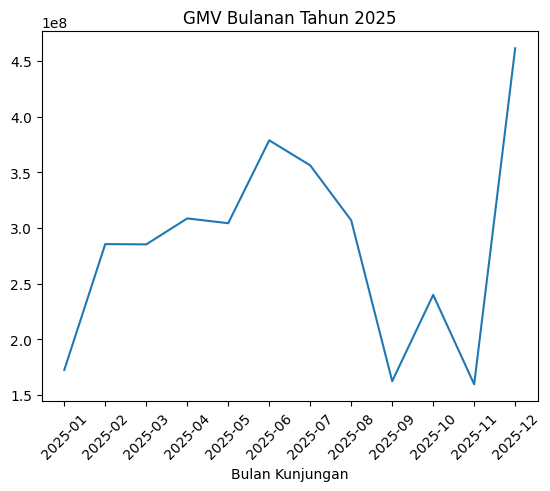

In [6]:
import matplotlib.pyplot as plt
plt.plot(gmv_bulanan['bulan_kunjungan'], gmv_bulanan['gmv'])
plt.title('GMV Bulanan Tahun 2025')
plt.xlabel('Bulan Kunjungan')
plt.xticks(rotation=45)
plt.show()

### 7. Mengubah Figure Size

**Keterangan:** Ukuran figure dilebarkan dengan figsize=(15,5) agar ke-12 bulan terlihat lebih jelas.

**Insight:** Dengan figure yang lebih lebar, naik-turunnya GMV tiap bulan, termasuk lonjakan di Desember, lebih mudah diikuti.

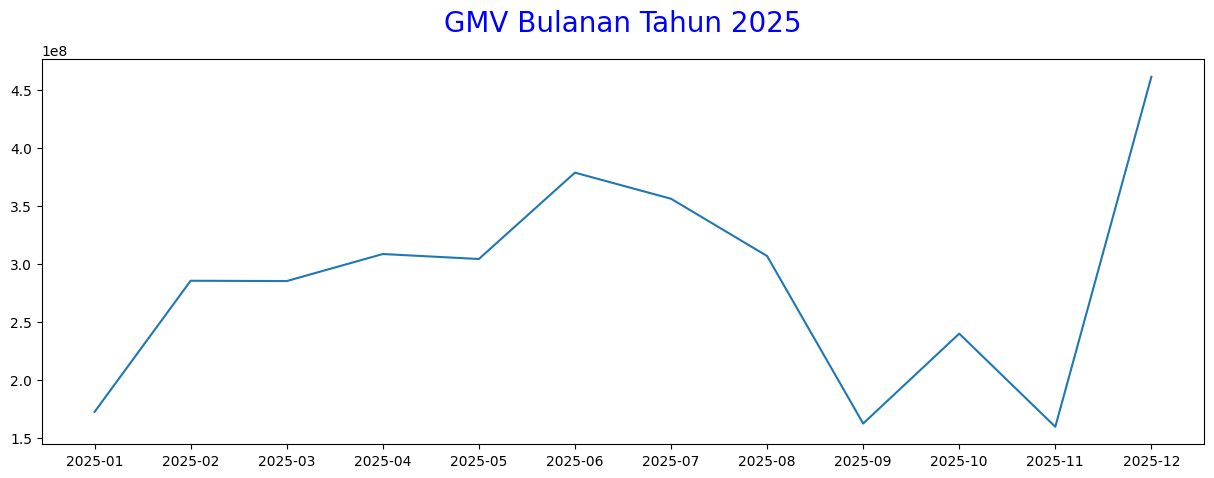

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
plt.plot(gmv_bulanan['bulan_kunjungan'], gmv_bulanan['gmv'])
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.show()

### 8. Menambahkan Title dan Axis Labels

**Keterangan:** Judul dan label sumbu ditambahkan agar jelas bahwa grafik menampilkan total GMV per bulan.

**Insight:** Grafik memuat total GMV per bulan sepanjang 2025, dengan sumbu y masih dalam rupiah (skala 1e8 = 100 juta).

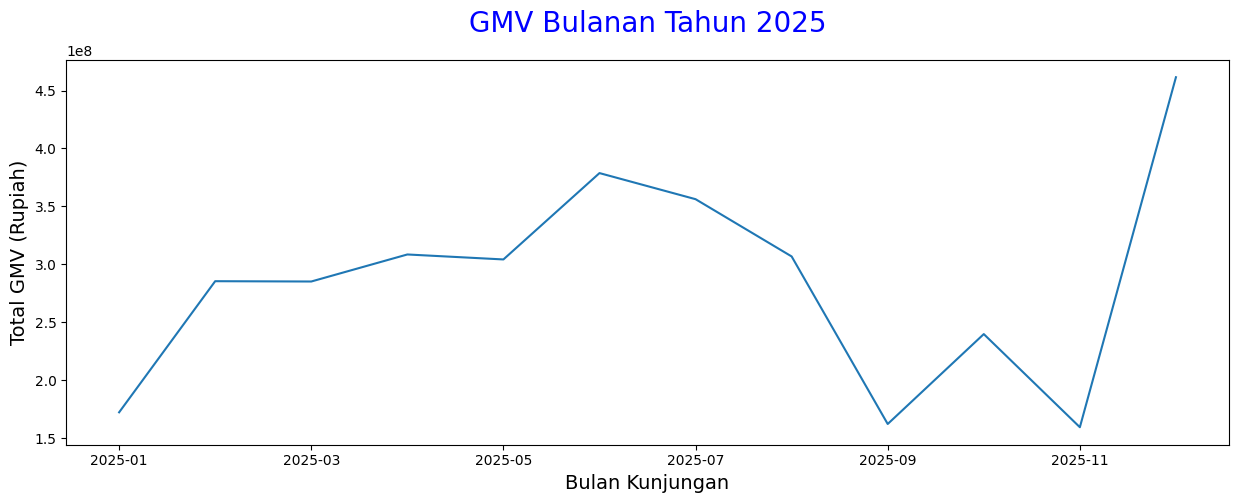

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot()
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=14)
plt.ylabel('Total GMV (Rupiah)', fontsize=14)
plt.show()

### 9. Modifikasi Line dan Point

**Keterangan:** Garis diberi warna hijau dengan titik bulat dan gaya garis-titik agar nilai tiap bulan mudah dilihat.

**Insight:** GMV turun berturut-turut dari Juni sampai September, naik di Oktober, turun lagi di November, lalu melonjak di Desember.

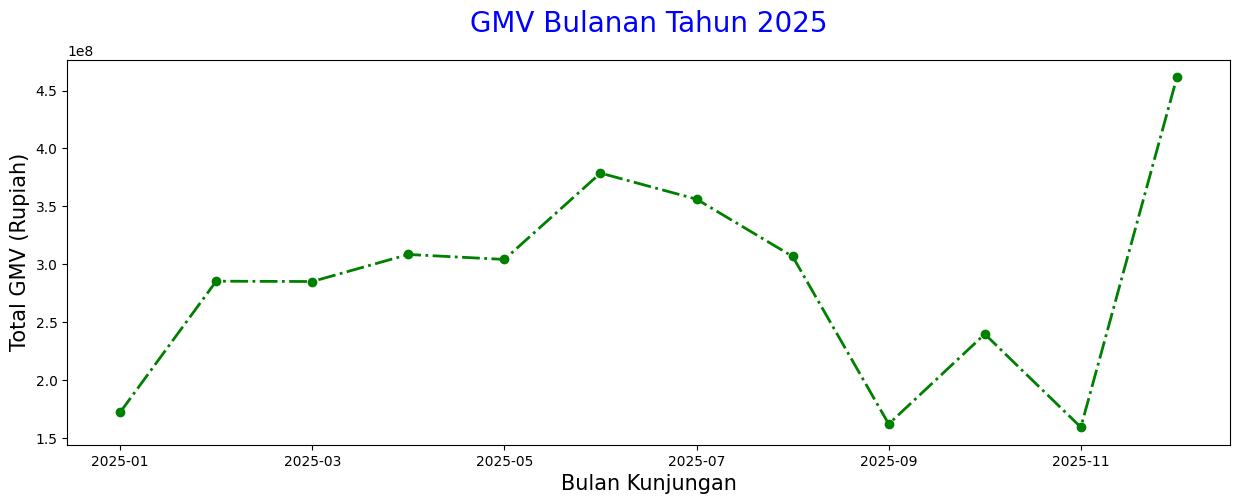

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot(color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Total GMV (Rupiah)', fontsize=15)
plt.show()

### 10. Modifikasi Grid

**Keterangan:** Grid ditambahkan sebagai garis bantu untuk membaca nilai titik pada sumbu y.

**Insight:** Dengan grid, GMV Juni (sekitar Rp379 juta) dan Desember (sekitar Rp461 juta) lebih mudah dibaca dari sumbu y.

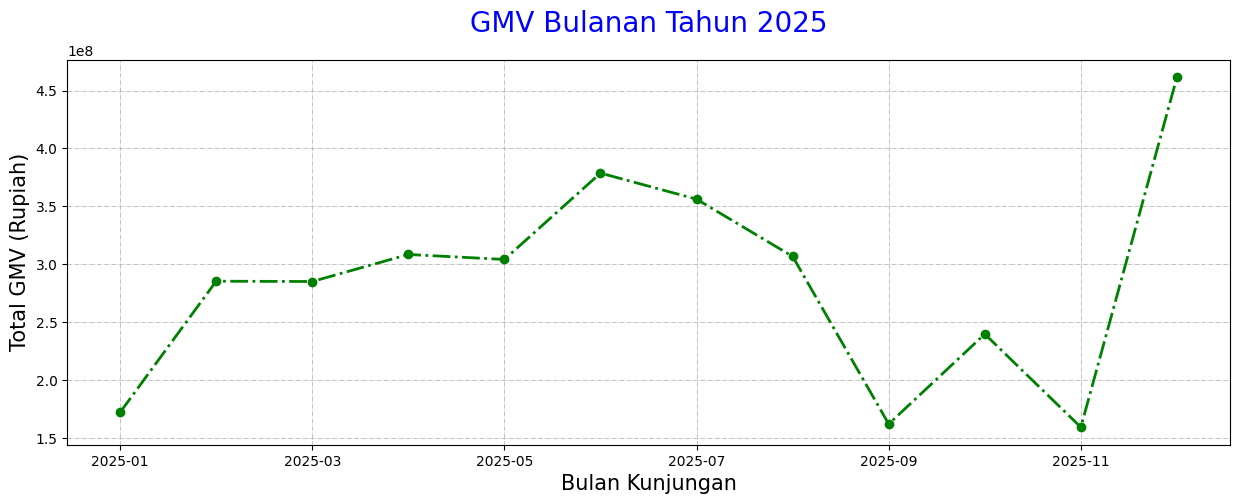

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot(color='green', marker='o', linestyle='-.', linewidth=2)
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Total GMV (Rupiah)', fontsize=15)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)
plt.show()

### 11. Menambahkan Informasi pada Plot

**Keterangan:** Sumbu y diubah ke juta rupiah, ditambah legenda dan teks merah yang menandai bulan dengan GMV tertinggi.

**Insight:** Puncak GMV terjadi pada Desember 2025 sebesar Rp461 juta, jauh di atas bulan lain, dan Juni berada di urutan kedua dengan Rp379 juta.

1.   List item
2.   List item



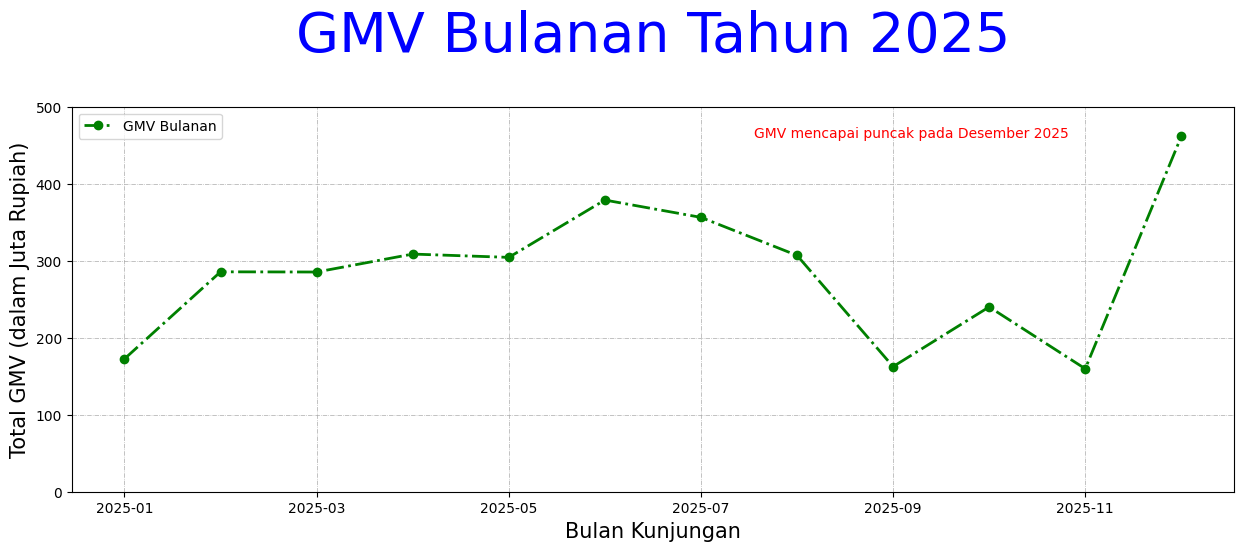

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
dataset.groupby(['bulan_kunjungan'])['gmv'].sum().plot(color='green', marker='o', linestyle='-.', linewidth=2, label='GMV Bulanan')
plt.title('GMV Bulanan Tahun 2025', loc='center', pad=40, fontsize=40, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Total GMV (dalam Juta Rupiah)', fontsize=15)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)
plt.ylim(ymin=0)
labels, location = plt.yticks()
plt.yticks(labels, (labels/1000000).astype(int))
plt.text(0.58, 0.82, "GMV mencapai puncak pada Desember 2025", transform=plt.gcf().transFigure, color='red')
plt.legend()
plt.show()

### 12. Visualisasi 2 - Bar Chart GMV per Destinasi

**Keterangan:** Bar chart horizontal ini membandingkan total GMV antar destinasi wisata, dari yang terbesar sampai terkecil.

**Insight:** Jatim Park 2 (Rp1.587 juta) dan Batu Secret Zoo (Rp1.274 juta) menyumbang sekitar 84% dari total GMV, sedangkan destinasi lain jauh lebih kecil.

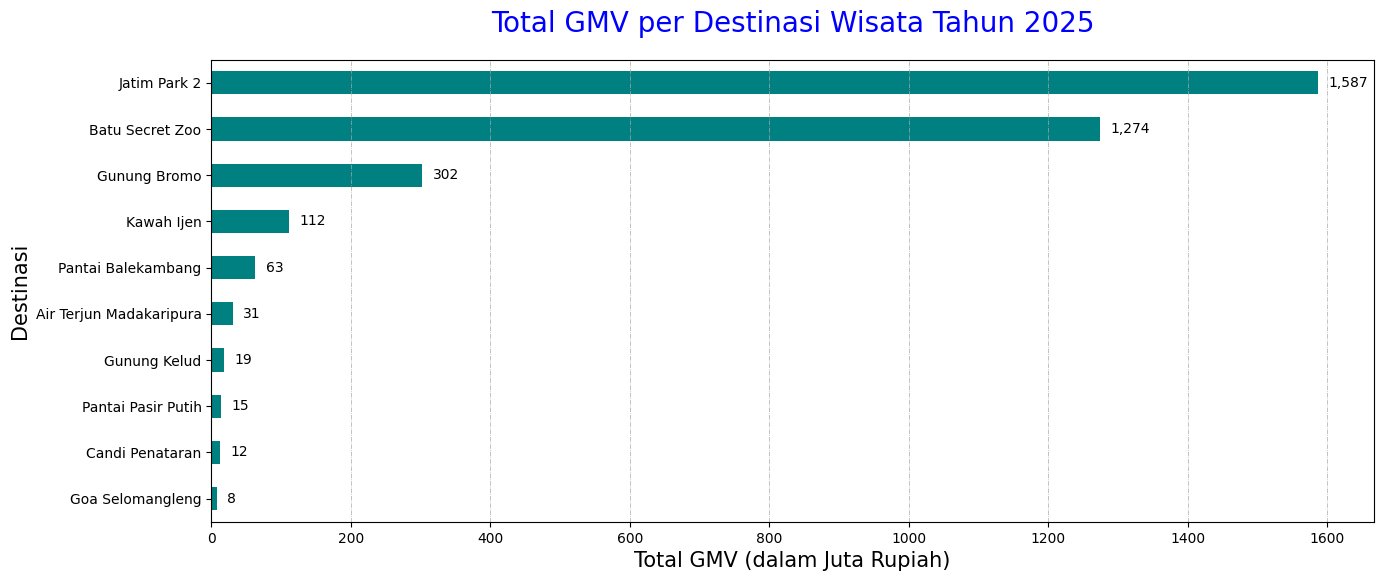

In [12]:
import matplotlib.pyplot as plt
gmv_destinasi = dataset.groupby('destinasi')['gmv'].sum().sort_values() / 1000000
plt.figure(figsize=(15,6))
gmv_destinasi.plot(kind='barh', color='teal')
plt.title('Total GMV per Destinasi Wisata Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Total GMV (dalam Juta Rupiah)', fontsize=15)
plt.ylabel('Destinasi', fontsize=15)
plt.grid(axis='x', color='darkgray', linestyle='-.', linewidth=0.5)
for i, nilai in enumerate(gmv_destinasi):
    plt.text(nilai + 15, i, f'{nilai:,.0f}', va='center')
plt.show()

### 13. Visualisasi 3 - Pie Chart Porsi Pengunjung per Jenis Wisata

**Keterangan:** Pie chart ini menunjukkan porsi jumlah pengunjung tiap jenis wisata terhadap total pengunjung.

**Insight:** Taman Rekreasi paling banyak dikunjungi (52,2%), disusul Gunung (28,2%) dan Pantai (10,6%), sedangkan Budaya & Sejarah (5,0%) dan Air Terjun (3,9%) paling sedikit.

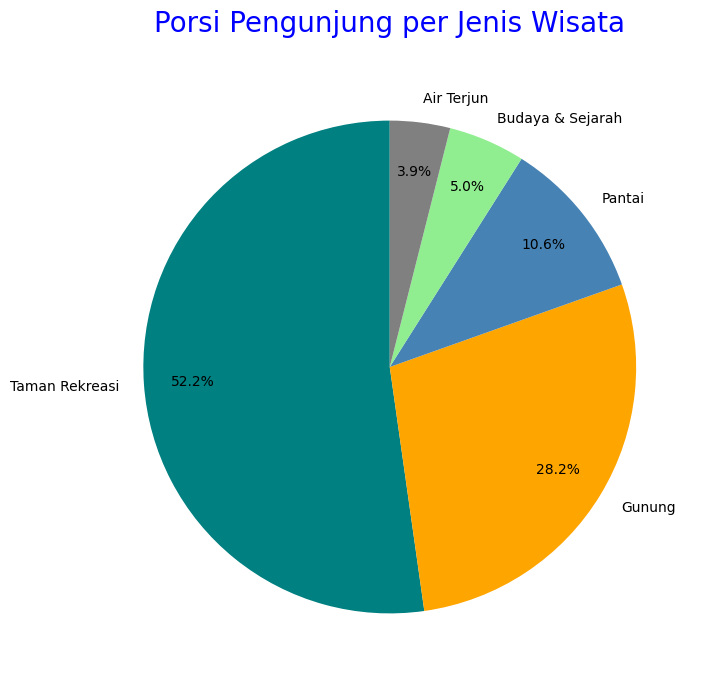

In [13]:
import matplotlib.pyplot as plt
pengunjung_jenis = dataset.groupby('jenis_wisata')['jumlah_pengunjung'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,8))
plt.pie(pengunjung_jenis, labels=pengunjung_jenis.index, autopct='%1.1f%%', startangle=90,
        colors=['teal', 'orange', 'steelblue', 'lightgreen', 'gray'], pctdistance=0.8)
plt.title('Porsi Pengunjung per Jenis Wisata', loc='center', pad=20, fontsize=20, color='blue')
plt.show()

### 14. Visualisasi 4 - Histogram Sebaran Rating

**Keterangan:** Histogram ini menunjukkan sebaran rating pengunjung, dan garis merah putus-putus adalah nilai rata-ratanya.

**Insight:** Rating rata-rata 4,21, dan kunjungan paling banyak berada pada rentang rating 4,2 sampai 4,6.

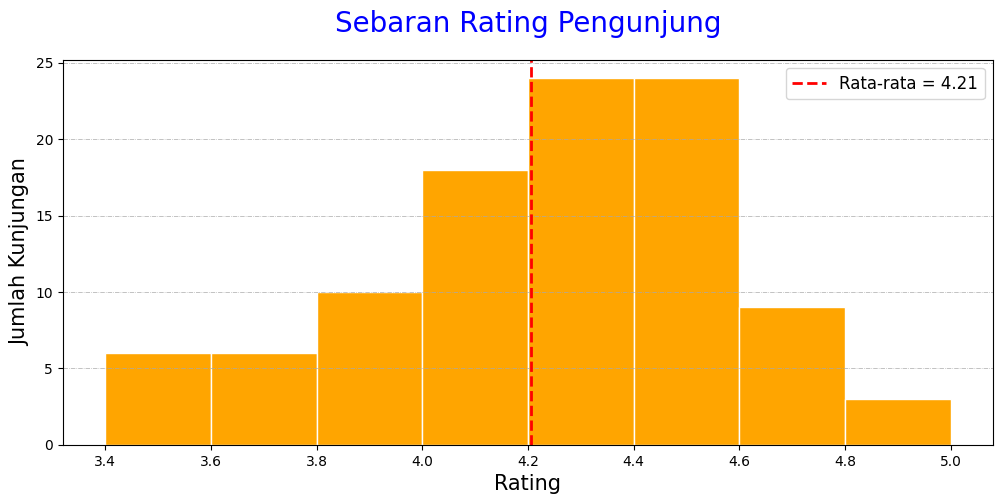

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.hist(dataset['rating'], bins=8, color='orange', edgecolor='white')
plt.axvline(dataset['rating'].mean(), color='red', linestyle='--', linewidth=2,
            label='Rata-rata = %.2f' % dataset['rating'].mean())
plt.title('Sebaran Rating Pengunjung', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Rating', fontsize=15)
plt.ylabel('Jumlah Kunjungan', fontsize=15)
plt.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
plt.legend(fontsize=12)
plt.show()

### 15. Visualisasi 5 - Scatter Plot Harga Tiket vs Jumlah Pengunjung

**Keterangan:** Scatter plot ini menunjukkan hubungan harga tiket (sumbu x) dengan jumlah pengunjung (sumbu y), dengan warna titik menurut jenis wisata.

**Insight:** Titik cenderung naik ke kanan (korelasi 0,59), artinya destinasi bertiket mahal cenderung lebih ramai, tetapi ini belum tentu sebab-akibat.

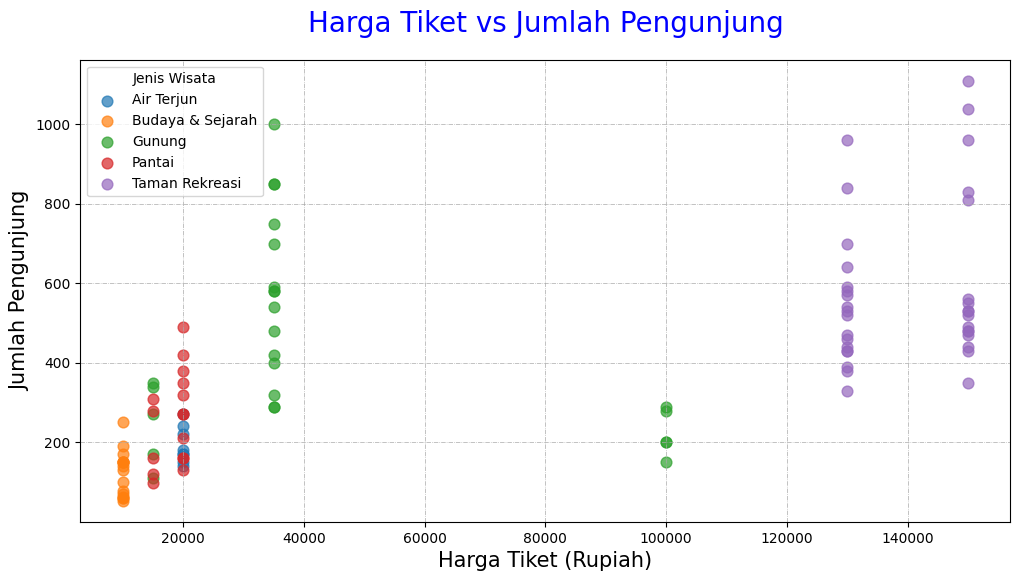

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
for jenis, grup in dataset.groupby('jenis_wisata'):
    plt.scatter(grup['harga_tiket'], grup['jumlah_pengunjung'], label=jenis, s=60, alpha=0.7)
plt.title('Harga Tiket vs Jumlah Pengunjung', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Harga Tiket (Rupiah)', fontsize=15)
plt.ylabel('Jumlah Pengunjung', fontsize=15)
plt.ticklabel_format(style='plain', axis='x')
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)
plt.legend(title='Jenis Wisata')
plt.show()

### 16. Visualisasi 6 - Box Plot Jumlah Pengunjung Menurut Cuaca

**Keterangan:** Box plot ini membandingkan sebaran jumlah pengunjung pada cuaca berawan, cerah, dan hujan.

**Insight:** Median pengunjung saat hujan (290) lebih rendah daripada saat berawan (350) dan cerah (390), sehingga hujan cenderung menurunkan kunjungan.

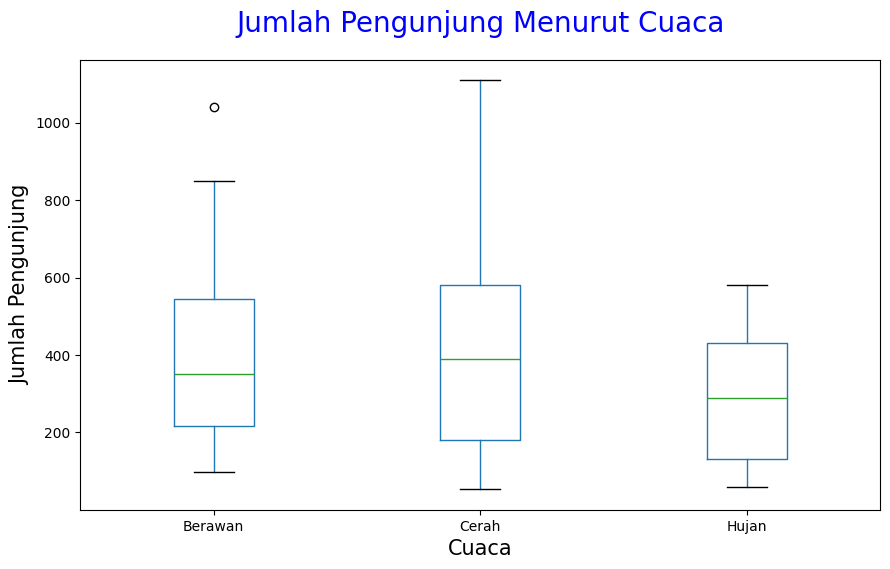

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
dataset.boxplot(column='jumlah_pengunjung', by='cuaca', grid=False, ax=plt.gca())
plt.suptitle('')
plt.title('Jumlah Pengunjung Menurut Cuaca', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Cuaca', fontsize=15)
plt.ylabel('Jumlah Pengunjung', fontsize=15)
plt.show()

### 17. Visualisasi 7 - Stacked Bar Chart GMV Bulanan per Jenis Wisata

**Keterangan:** Stacked bar ini menunjukkan total GMV tiap bulan beserta kontribusi tiap jenis wisata.

**Insight:** Taman Rekreasi menyumbang GMV terbesar di setiap bulan, yaitu sekitar 84% dari GMV setahun.

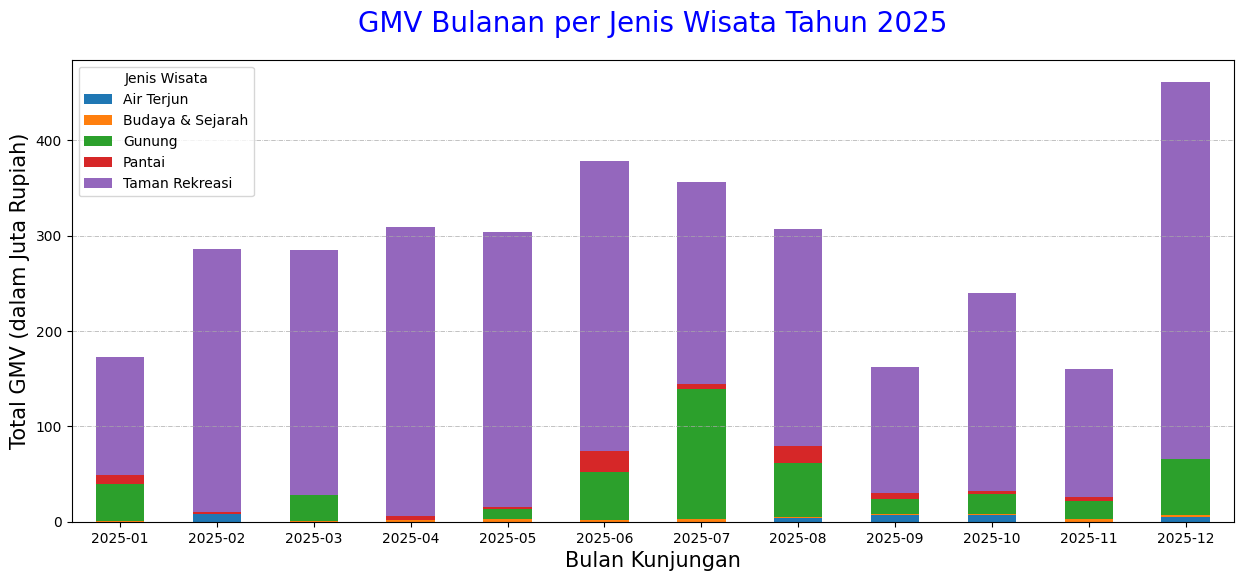

In [17]:
import matplotlib.pyplot as plt
gmv_jenis_bulan = dataset.pivot_table(index='bulan_kunjungan', columns='jenis_wisata',
                                      values='gmv', aggfunc='sum', fill_value=0) / 1000000
gmv_jenis_bulan.plot(kind='bar', stacked=True, figsize=(15,6))
plt.title('GMV Bulanan per Jenis Wisata Tahun 2025', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Total GMV (dalam Juta Rupiah)', fontsize=15)
plt.xticks(rotation=0)
plt.grid(axis='y', color='darkgray', linestyle='-.', linewidth=0.5)
plt.legend(title='Jenis Wisata')
plt.show()

### 18. Visualisasi 8 - Heatmap Jumlah Pengunjung per Bulan dan Jenis Wisata

**Keterangan:** Heatmap ini menunjukkan jumlah pengunjung menurut jenis wisata (baris) dan bulan (kolom); makin gelap warnanya, makin banyak pengunjungnya.

**Insight:** Kotak paling gelap adalah Gunung pada Juli (2.800 pengunjung), hampir sama dengan Taman Rekreasi pada Desember (2.790 pengunjung).

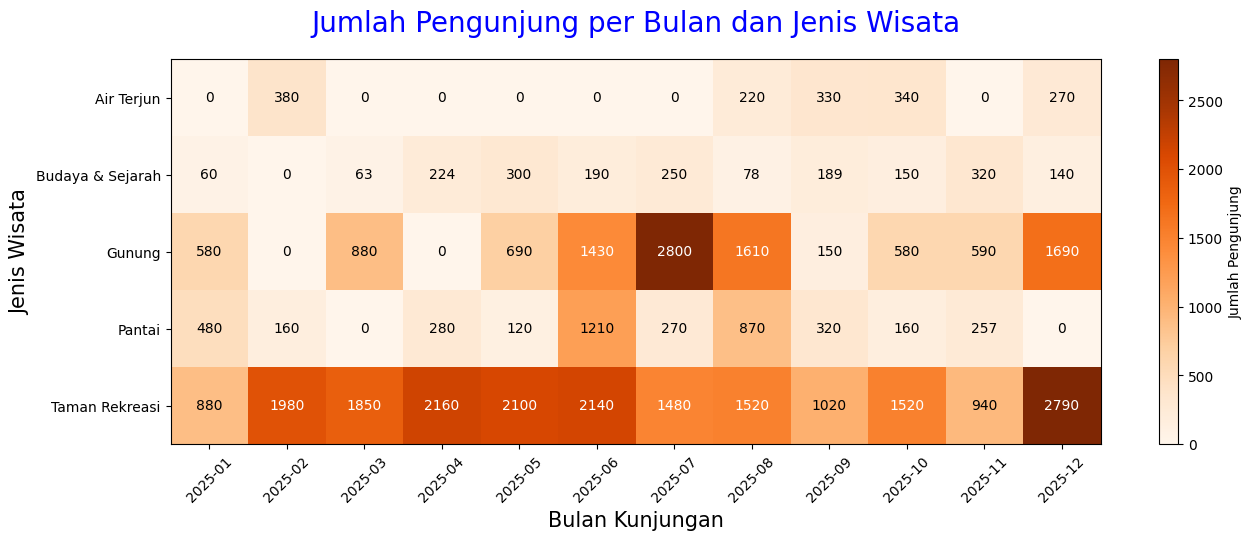

In [18]:
import matplotlib.pyplot as plt
pengunjung_heat = dataset.pivot_table(index='jenis_wisata', columns='bulan_kunjungan',
                                      values='jumlah_pengunjung', aggfunc='sum', fill_value=0)
plt.figure(figsize=(15,5))
plt.imshow(pengunjung_heat, cmap='Oranges', aspect='auto')
plt.colorbar(label='Jumlah Pengunjung')
plt.xticks(range(len(pengunjung_heat.columns)), pengunjung_heat.columns, rotation=45)
plt.yticks(range(len(pengunjung_heat.index)), pengunjung_heat.index)
for i in range(pengunjung_heat.shape[0]):
    for j in range(pengunjung_heat.shape[1]):
        nilai = pengunjung_heat.iloc[i, j]
        warna = 'white' if nilai > pengunjung_heat.values.max() / 2 else 'black'
        plt.text(j, i, nilai, ha='center', va='center', fontsize=10, color=warna)
plt.title('Jumlah Pengunjung per Bulan dan Jenis Wisata', loc='center', pad=20, fontsize=20, color='blue')
plt.xlabel('Bulan Kunjungan', fontsize=15)
plt.ylabel('Jenis Wisata', fontsize=15)
plt.show()

### 19. Visualisasi 9 - Beberapa Grafik dalam Satu Figure (Subplots)

**Keterangan:** Dashboard ini menampilkan empat grafik ringkasan (GMV bulanan, 5 destinasi teratas, sebaran rating, rata-rata pengunjung menurut cuaca) dalam satu figure.

**Insight:** Dashboard merangkum bahwa GMV memuncak di Desember, Jatim Park 2 memimpin GMV antar destinasi, dan rata-rata pengunjung paling rendah terjadi saat hujan (286).

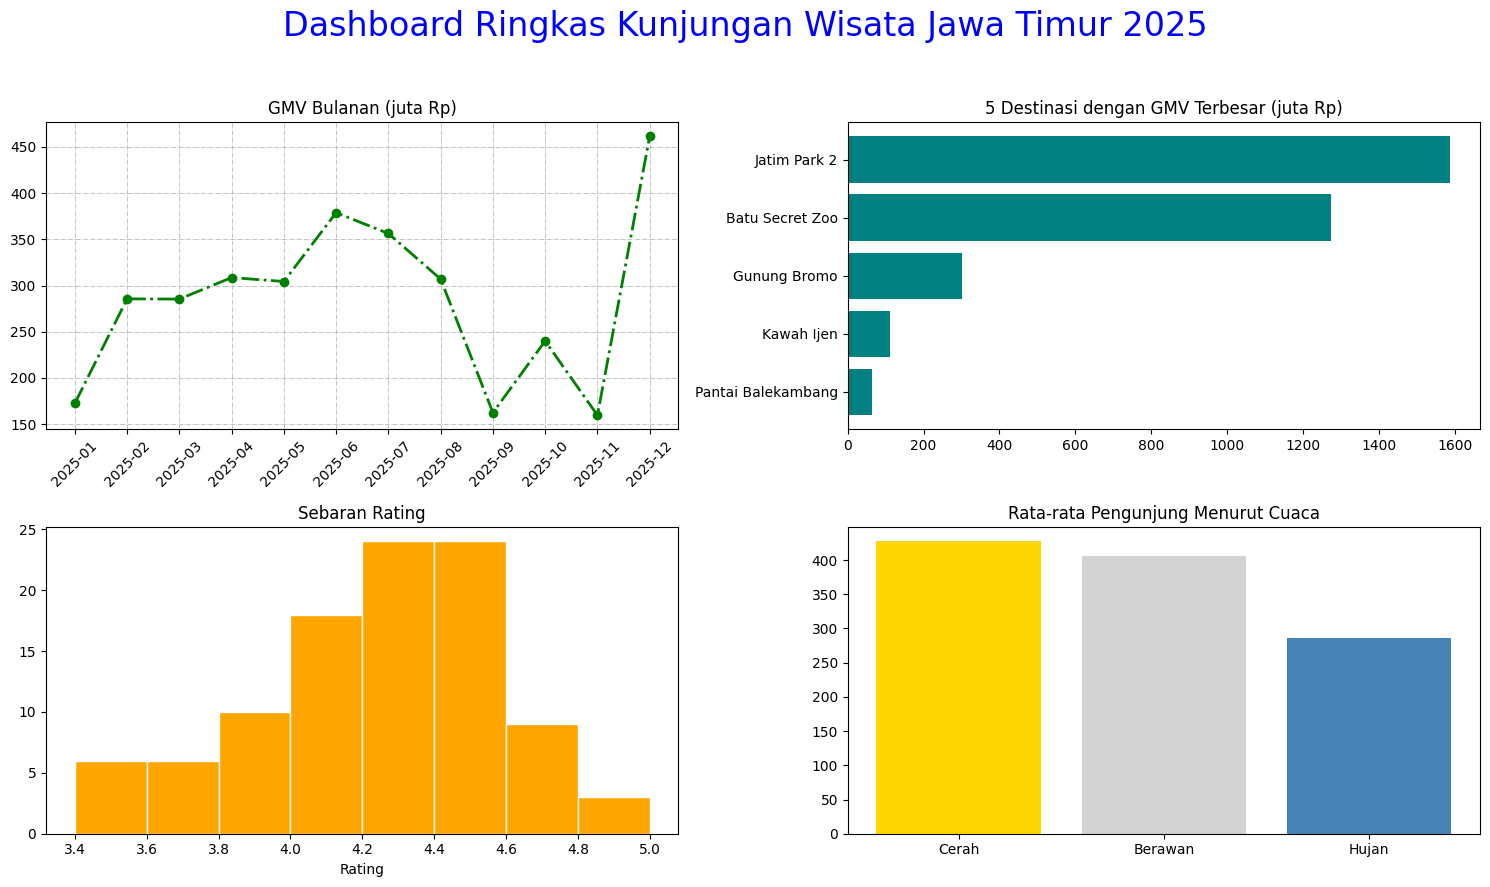

In [19]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(15,9))
fig.suptitle('Dashboard Ringkas Kunjungan Wisata Jawa Timur 2025', fontsize=24, color='blue')

# (1) GMV bulanan
axes[0,0].plot(gmv_bulanan['bulan_kunjungan'], gmv_bulanan['gmv'] / 1000000, color='green', marker='o', linestyle='-.', linewidth=2)
axes[0,0].set_title('GMV Bulanan (juta Rp)')
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].grid(color='darkgray', linestyle='-.', linewidth=0.5)

# (2) 5 destinasi dengan GMV terbesar
top5 = dataset.groupby('destinasi')['gmv'].sum().sort_values(ascending=False).head(5)[::-1] / 1000000
axes[0,1].barh(top5.index, top5.values, color='teal')
axes[0,1].set_title('5 Destinasi dengan GMV Terbesar (juta Rp)')

# (3) Sebaran rating
axes[1,0].hist(dataset['rating'], bins=8, color='orange', edgecolor='white')
axes[1,0].set_title('Sebaran Rating')
axes[1,0].set_xlabel('Rating')

# (4) Rata-rata pengunjung menurut cuaca
rata_cuaca = dataset.groupby('cuaca')['jumlah_pengunjung'].mean().reindex(['Cerah', 'Berawan', 'Hujan'])
axes[1,1].bar(rata_cuaca.index, rata_cuaca.values, color=['gold', 'lightgray', 'steelblue'])
axes[1,1].set_title('Rata-rata Pengunjung Menurut Cuaca')

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## KESIMPULAN

1. **Gambaran data.** Dataset simulasi berisi 100 catatan kunjungan di 10 destinasi wisata Jawa Timur sepanjang 2025, dengan total GMV Rp3.422.145.000 atau sekitar Rp3,42 miliar.
2. **Tren waktu (line chart).** GMV memuncak pada Desember (Rp461 juta), Juni menjadi puncak kedua (Rp379 juta), dan GMV terendah terjadi pada November (Rp160 juta).
3. **Perbandingan dan porsi (bar chart, pie chart, stacked bar).** Jatim Park 2 dan Batu Secret Zoo menyumbang sekitar 84% GMV. Taman Rekreasi paling banyak dikunjungi (52,2%) dan menjadi penyumbang GMV terbesar di setiap bulan.
4. **Sebaran dan hubungan (histogram, scatter plot, box plot, heatmap).** Rating rata-rata 4,21. Harga tiket berkorelasi positif dengan jumlah pengunjung (0,59), tetapi belum tentu sebab-akibat. Median pengunjung saat hujan (290) lebih rendah daripada saat cerah (390).
5. **Pemilihan visualisasi.** Line chart cocok untuk tren waktu, bar chart untuk perbandingan antar kategori, pie chart untuk porsi, histogram untuk sebaran, scatter plot untuk hubungan dua angka, box plot untuk membandingkan sebaran antar kelompok, stacked bar untuk komposisi, heatmap untuk pola dua dimensi, dan subplots untuk ringkasan.
6. **Keterbatasan.** Data dibuat sendiri (simulasi) dan hanya 100 baris, sehingga pola yang terlihat hanya untuk latihan. Kesimpulan yang sesungguhnya memerlukan data nyata dengan jumlah yang lebih banyak.